# AI-driven Water Quality Monitoring: Person B (Modelling)
**Goal:** predict water potability (`Potability`: 1 = safe, 0 = not safe) from 9 physicochemical measurements.
**Input from Person A:** `train.csv`, `test.csv` (stratified 80/20 split, median-imputed on train only, + 3 missing-indicator flags).
**This notebook covers:** baselines, hyper-parameter tuning, cross-validation, model comparison, threshold tuning, ensemble, SHAP explainability.
**Deliverables for Person C:** `models/best_model.joblib`, `models/model_meta.json`, `predict_utils.py`, `outputs_B/results_table.csv`.

Rules followed (so the numbers are trustworthy):
- The **test set is touched once**, at the end. All selection (model, hyper-parameters, threshold) uses cross-validation on train only.
- Class imbalance (61/39) is handled with class weights inside each model, no resampling before the split.
- Metrics: F1, ROC-AUC, PR-AUC, balanced accuracy, and accuracy (reported but not used to choose).

## 1. Setup

In [1]:
!pip -q install xgboost lightgbm shap kagglehub 2>/dev/null
import os, json, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, cross_validate,
                                     RandomizedSearchCV, cross_val_predict, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, average_precision_score,
                             balanced_accuracy_score, precision_score, recall_score,
                             confusion_matrix, roc_curve, precision_recall_curve, classification_report)
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
OUT = "outputs_B"; MODELS = "models"
os.makedirs(OUT, exist_ok=True); os.makedirs(MODELS, exist_ok=True)
TARGET = "Potability"

## 2. Load Person A's data
Looks for `train.csv` / `test.csv` from Person A. If they are not found it rebuilds them from the raw Kaggle file **with exactly Person A's steps** (same flags, median imputer fitted on train, `random_state=42`, 80/20 stratified), so results are identical either way.

In [2]:
def find_files():
    for d in [".", "outputs", "/content", "/content/outputs", "/kaggle/working/outputs", "/kaggle/input/water-potability-eda"]:
        if os.path.exists(f"{d}/train.csv") and os.path.exists(f"{d}/test.csv"):
            return f"{d}/train.csv", f"{d}/test.csv"
    return None

def rebuild_from_raw():
    raw = None
    for p in ["water_potability.csv", "/kaggle/input/datasets/adityakadiwal/water-potability/water_potability.csv"]:
        if os.path.exists(p): raw = pd.read_csv(p); break
    if raw is None:
        try:
            import kagglehub
            raw = pd.read_csv(os.path.join(kagglehub.dataset_download("adityakadiwal/water-potability"), "water_potability.csv"))
        except Exception as e:
            print("kagglehub failed:", e)
            from google.colab import files
            raw = pd.read_csv(list(files.upload().keys())[0])
    feats = [c for c in raw.columns if c != TARGET]
    d = raw.drop_duplicates().reset_index(drop=True)
    for c in ["ph", "Sulfate", "Trihalomethanes"]:
        d[f"{c}_was_missing"] = d[c].isna().astype(int)
    X, y = d.drop(columns=TARGET), d[TARGET]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    imp = SimpleImputer(strategy="median").fit(Xtr[feats])
    Xtr, Xte = Xtr.copy(), Xte.copy()
    Xtr[feats] = imp.transform(Xtr[feats]); Xte[feats] = imp.transform(Xte[feats])
    return pd.concat([Xtr, ytr], axis=1), pd.concat([Xte, yte], axis=1)

paths = find_files()
if paths:
    train, test = pd.read_csv(paths[0]), pd.read_csv(paths[1]); print("Loaded Person A files:", paths)
else:
    train, test = rebuild_from_raw(); print("Rebuilt train/test from raw data")

FEATURES = [c for c in train.columns if c != TARGET]
BASE_FEATURES = [c for c in FEATURES if not c.endswith("_was_missing")]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print("train", X_train.shape, "| test", X_test.shape)
print("features:", FEATURES)
print("train class %:", (y_train.value_counts(normalize=True)*100).round(1).to_dict())
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

Rebuilt train/test from raw data
train (2620, 12) | test (656, 12)
features: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'ph_was_missing', 'Sulfate_was_missing', 'Trihalomethanes_was_missing']
train class %: {0: 61.0, 1: 39.0}


## 3. Baseline models (5-fold x 2 repeated stratified CV on train)
All models use class weighting for the 61/39 imbalance. Scale-sensitive models (LogReg, KNN, SVM) get a `StandardScaler` **inside the pipeline**, so it is fitted per fold (no leakage).

In [3]:
spw = (y_train == 0).sum() / (y_train == 1).sum()   # scale_pos_weight for boosted trees
scaled = lambda m: Pipeline([("sc", StandardScaler()), ("m", m)])

baselines = {
    "Dummy (majority)":     DummyClassifier(strategy="prior"),
    "Logistic Regression":  scaled(LogisticRegression(class_weight="balanced", max_iter=2000)),
    "KNN":                  scaled(KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)":            scaled(SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE)),
    "Decision Tree":        DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees":          ExtraTreesClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost":              XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=spw,
                                          eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM":             LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight="balanced",
                                           n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
}
SCORING = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)

rows = []
for name, model in baselines.items():
    t = time.time()
    r = cross_validate(model, X_train, y_train, cv=cv_rep, scoring=SCORING, n_jobs=-1)
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in SCORING},
                 "f1_std": r["test_f1"].std(), "auc_std": r["test_roc_auc"].std()})
    print(f"{name:20s} F1={rows[-1]['f1']:.3f}  AUC={rows[-1]['roc_auc']:.3f}  ({time.time()-t:.0f}s)")
baseline_df = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)
baseline_df.round(3).to_csv(f"{OUT}/baseline_cv.csv")
baseline_df.round(3)

Dummy (majority)     F1=0.000  AUC=0.500  (2s)
Logistic Regression  F1=0.436  AUC=0.493  (0s)
KNN                  F1=0.366  AUC=0.626  (0s)
SVM (RBF)            F1=0.552  AUC=0.686  (5s)
Decision Tree        F1=0.375  AUC=0.587  (0s)
Random Forest        F1=0.401  AUC=0.682  (11s)
Extra Trees          F1=0.395  AUC=0.680  (6s)
Gradient Boosting    F1=0.345  AUC=0.627  (4s)
XGBoost              F1=0.513  AUC=0.653  (2s)
LightGBM             F1=0.515  AUC=0.667  (595s)


,accuracy,balanced_acc,f1,roc_auc,pr_auc,f1_std,auc_std
model,,,,,,,
SVM (RBF),0.648,0.631,0.552,0.686,0.597,0.031,0.018
Random Forest,0.669,0.600,0.401,0.682,0.600,0.035,0.018
Extra Trees,0.668,0.598,0.395,0.680,0.596,0.030,0.024
LightGBM,0.641,0.614,0.515,0.667,0.581,0.019,0.013
XGBoost,0.626,0.605,0.513,0.653,0.568,0.035,0.023
Gradient Boosting,0.637,0.567,0.345,0.627,0.541,0.028,0.022
KNN,0.635,0.569,0.366,0.626,0.514,0.029,0.014
Decision Tree,0.610,0.559,0.375,0.587,0.471,0.100,0.033
Dummy (majority),0.610,0.500,0.000,0.500,0.390,0.000,0.000


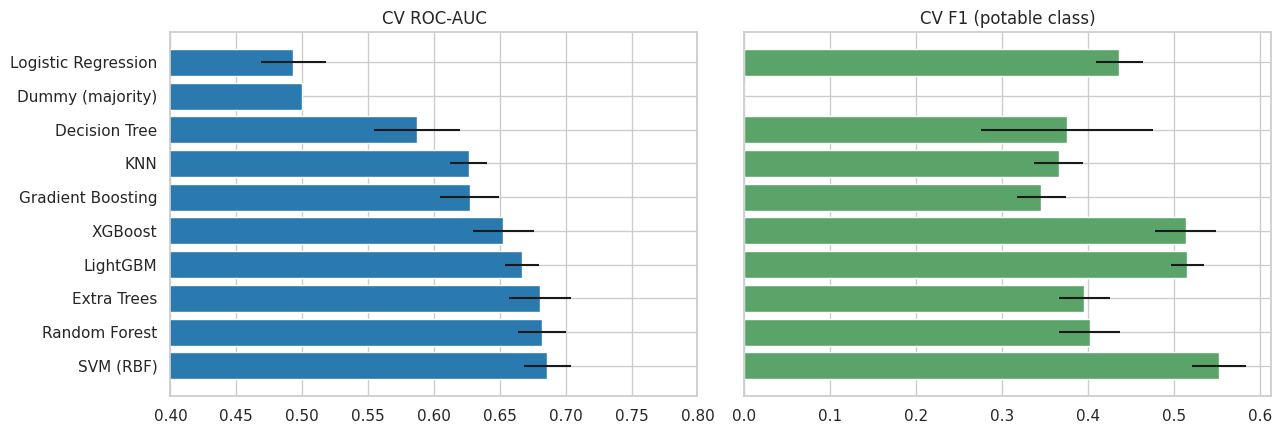

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
order = baseline_df.index
ax[0].barh(order, baseline_df["roc_auc"], xerr=baseline_df["auc_std"], color="#2a7ab0"); ax[0].set_title("CV ROC-AUC"); ax[0].set_xlim(0.4, 0.8)
ax[1].barh(order, baseline_df["f1"], xerr=baseline_df["f1_std"], color="#5aa469"); ax[1].set_title("CV F1 (potable class)")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.savefig(f"{OUT}/baseline_comparison.png", dpi=130); plt.show()

## 4. Hyper-parameter tuning
`RandomizedSearchCV` (5-fold stratified, scored by **ROC-AUC**, which is threshold-free and robust to imbalance) for the four strongest families. Increase `N_ITER` for the final report (e.g. 60); 12 keeps this demo fast (a few minutes on Colab).

In [5]:
N_ITER = 12
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
        {"n_estimators": randint(150, 400), "max_depth": [None, 8, 12, 16, 24],
         "min_samples_leaf": randint(1, 9), "max_features": ["sqrt", "log2", 0.5]}),
    "XGBoost": (
        XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE),
        {"n_estimators": randint(150, 400), "max_depth": randint(3, 9), "learning_rate": loguniform(0.01, 0.2),
         "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.6, 0.4),
         "min_child_weight": randint(1, 9), "reg_lambda": loguniform(0.1, 10)}),
    "LightGBM": (
        LGBMClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
        {"n_estimators": randint(150, 400), "num_leaves": randint(15, 80), "learning_rate": loguniform(0.01, 0.2),
         "min_child_samples": randint(10, 60), "subsample": uniform(0.6, 0.4), "subsample_freq": [1],
         "colsample_bytree": uniform(0.6, 0.4), "reg_lambda": loguniform(0.1, 10)}),
    "SVM (RBF)": (
        scaled(SVC(class_weight="balanced", random_state=RANDOM_STATE)),
        {"m__C": loguniform(0.3, 50), "m__gamma": loguniform(1e-3, 1)}),
}
tuned, tune_rows = {}, []
for name, (est, space) in search_spaces.items():
    t = time.time()
    s = RandomizedSearchCV(est, space, n_iter=N_ITER, scoring="roc_auc", cv=cv5, n_jobs=-1,
                           random_state=RANDOM_STATE, refit=True)
    s.fit(X_train, y_train)
    tuned[name] = s.best_estimator_
    if name == "SVM (RBF)": tuned[name].set_params(m__probability=True)   # needed for predict_proba / ensemble
    tune_rows.append({"model": name, "best_cv_auc": s.best_score_, "best_params": s.best_params_})
    print(f"{name:14s} best CV AUC = {s.best_score_:.3f}  ({time.time()-t:.0f}s)")
pd.DataFrame(tune_rows).to_csv(f"{OUT}/tuning_results.csv", index=False)
pd.DataFrame(tune_rows).set_index("model")

Random Forest  best CV AUC = 0.694  (58s)
XGBoost        best CV AUC = 0.682  (12s)
LightGBM       best CV AUC = 0.682  (4264s)
SVM (RBF)      best CV AUC = 0.682  (8s)


,best_cv_auc,best_params
model,,
Random Forest,0.694426,"{'max_depth': 12, 'max_features': 0.5, 'min_sa..."
XGBoost,0.682203,"{'colsample_bytree': 0.9687496940092467, 'lear..."
LightGBM,0.682437,"{'colsample_bytree': 0.9895022075365837, 'lear..."
SVM (RBF),0.682089,"{'m__C': 12.691152977202412, 'm__gamma': 0.062..."


## 5. Ensemble of the tuned models (soft voting)

In [6]:
ensemble = VotingClassifier([(n.split()[0], m) for n, m in tuned.items()], voting="soft", n_jobs=1)
tuned["Soft-Voting Ensemble"] = ensemble

cv_rows = []
for name, model in tuned.items():
    r = cross_validate(model, X_train, y_train, cv=cv5, scoring=SCORING, n_jobs=-1)
    cv_rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in SCORING}})
tuned_cv = pd.DataFrame(cv_rows).set_index("model").sort_values("roc_auc", ascending=False)
tuned_cv.round(3).to_csv(f"{OUT}/tuned_cv.csv")
tuned_cv.round(3)

,accuracy,balanced_acc,f1,roc_auc,pr_auc
model,,,,,
Soft-Voting Ensemble,0.676,0.636,0.521,0.701,0.614
Random Forest,0.665,0.618,0.484,0.694,0.606
LightGBM,0.643,0.624,0.540,0.682,0.588
XGBoost,0.657,0.630,0.536,0.682,0.596
SVM (RBF),0.642,0.630,0.555,0.682,0.587


## 6. Choose the final model and decision threshold (still using train only)
Model = highest CV ROC-AUC. Threshold = the cut-off that maximises F1 on **out-of-fold** predictions. The default 0.5 is rarely best for an imbalanced problem.

Selected model: Soft-Voting Ensemble
Best OOF threshold = 0.38  (F1 0.600 vs 0.522 at 0.50)


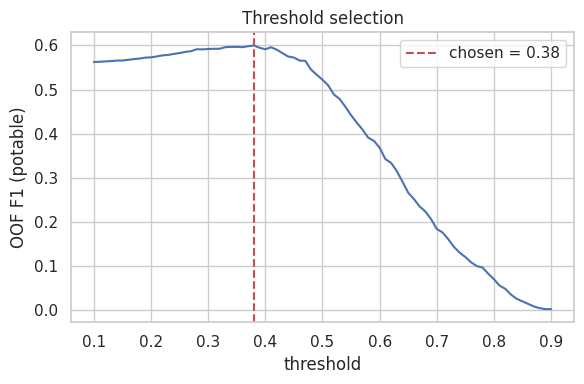

In [7]:
best_name = tuned_cv.index[0]
best_model = tuned[best_name]
print("Selected model:", best_name)

oof = cross_val_predict(best_model, X_train, y_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
ths = np.linspace(0.1, 0.9, 81)
f1s = [f1_score(y_train, oof >= t) for t in ths]
THRESHOLD = float(ths[int(np.argmax(f1s))])
print(f"Best OOF threshold = {THRESHOLD:.2f}  (F1 {max(f1s):.3f} vs {f1_score(y_train, oof>=0.5):.3f} at 0.50)")

plt.figure(figsize=(6, 4)); plt.plot(ths, f1s); plt.axvline(THRESHOLD, color="r", ls="--", label=f"chosen = {THRESHOLD:.2f}")
plt.xlabel("threshold"); plt.ylabel("OOF F1 (potable)"); plt.legend(); plt.title("Threshold selection")
plt.tight_layout(); plt.savefig(f"{OUT}/threshold.png", dpi=130); plt.show()

## 7. Final evaluation on the held-out test set (used once)

In [8]:
def evaluate(model, name, threshold=0.5):
    p = model.predict_proba(X_test)[:, 1]; pred = (p >= threshold).astype(int)
    return {"model": name, "threshold": round(threshold, 2),
            "accuracy": accuracy_score(y_test, pred), "balanced_acc": balanced_accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, p),
            "pr_auc": average_precision_score(y_test, p)}, p

rows, probs = [], {}
for name, model in tuned.items():
    model.fit(X_train, y_train)                 # refit on full train (ensemble members are fitted clones)
    r, probs[name] = evaluate(model, name); rows.append(r)
r, probs["best@tuned_thr"] = evaluate(best_model, f"{best_name} (tuned threshold)", THRESHOLD); rows.append(r)
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
r, _ = evaluate(dummy, "Dummy (majority)"); rows.append(r)

results = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)
results.round(3).to_csv(f"{OUT}/results_table.csv")
results.round(3)

,threshold,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,,
Random Forest,0.50,0.672,0.626,0.620,0.414,0.496,0.677,0.619
XGBoost,0.50,0.646,0.619,0.553,0.492,0.521,0.676,0.618
Soft-Voting Ensemble,0.50,0.657,0.615,0.583,0.426,0.492,0.670,0.610
Soft-Voting Ensemble (tuned threshold),0.38,0.578,0.605,0.473,0.730,0.575,0.670,0.610
LightGBM,0.50,0.634,0.607,0.534,0.484,0.508,0.654,0.598
SVM (RBF),0.50,0.643,0.587,0.574,0.332,0.421,0.643,0.556
Dummy (majority),0.50,0.610,0.500,0.000,0.000,0.000,0.500,0.390


              precision    recall  f1-score   support

 Not potable       0.74      0.48      0.58       400
     Potable       0.47      0.73      0.57       256

    accuracy                           0.58       656
   macro avg       0.60      0.61      0.58       656
weighted avg       0.63      0.58      0.58       656



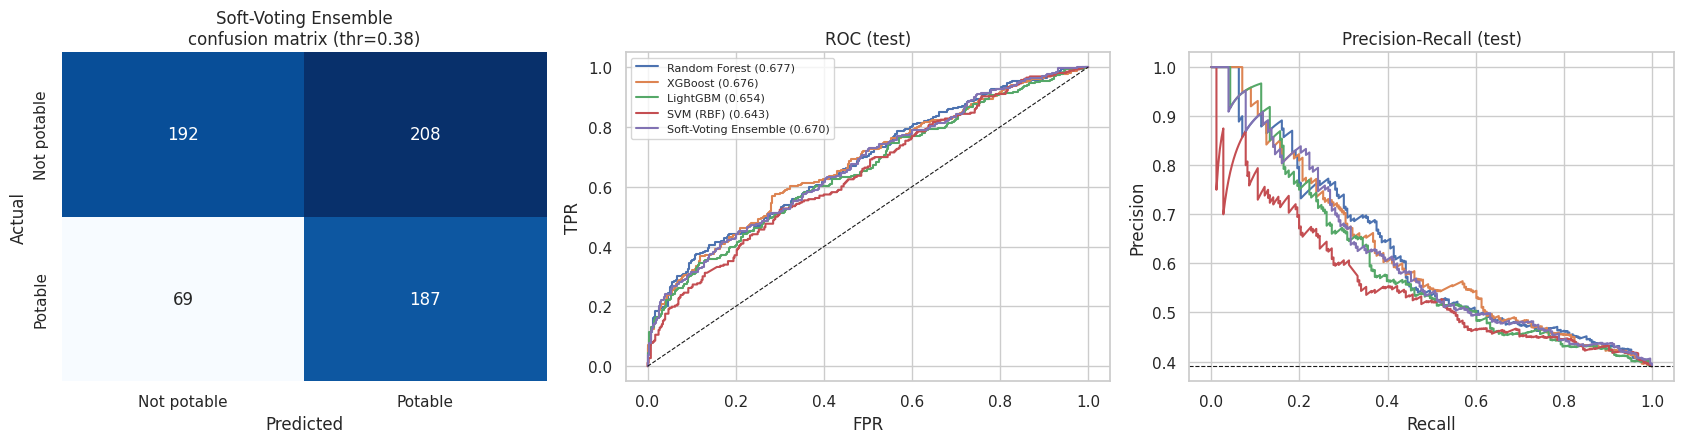

In [9]:
print(classification_report(y_test, (probs["best@tuned_thr"] >= THRESHOLD).astype(int),
                            target_names=["Not potable", "Potable"]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
pred = (probs["best@tuned_thr"] >= THRESHOLD).astype(int)
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Not potable", "Potable"], yticklabels=["Not potable", "Potable"])
ax[0].set_title(f"{best_name}\nconfusion matrix (thr={THRESHOLD:.2f})"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
for n in tuned:
    fpr, tpr, _ = roc_curve(y_test, probs[n]); ax[1].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, probs[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, probs[n]); ax[2].plot(rc, pr, label=n)
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_title("ROC (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(fontsize=8)
ax[2].axhline(y_test.mean(), color="k", ls="--", lw=.8); ax[2].set_title("Precision-Recall (test)"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
plt.tight_layout(); plt.savefig(f"{OUT}/test_evaluation.png", dpi=130); plt.show()

## 8. Explainability: SHAP and permutation importance
Which water parameters drive the prediction? Uses the tuned XGBoost (a tree model, so exact SHAP values are fast). Permutation importance on the selected model is a model-agnostic cross-check.

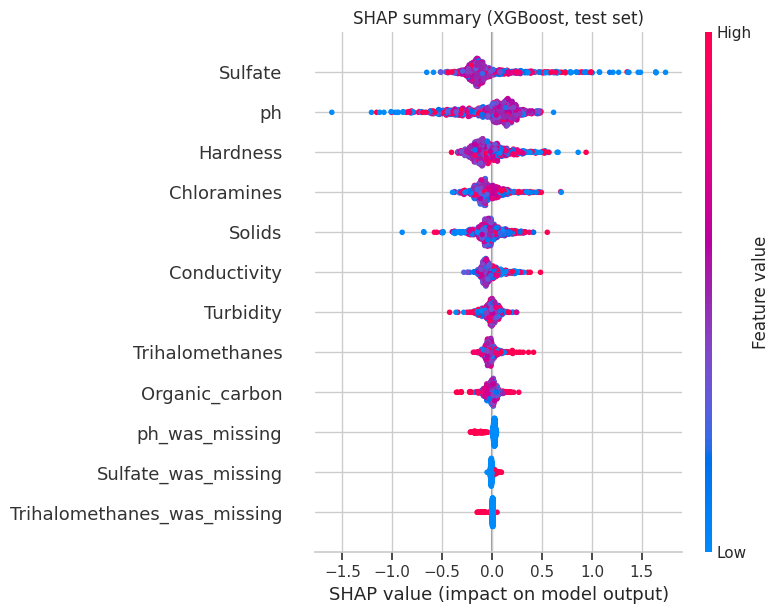

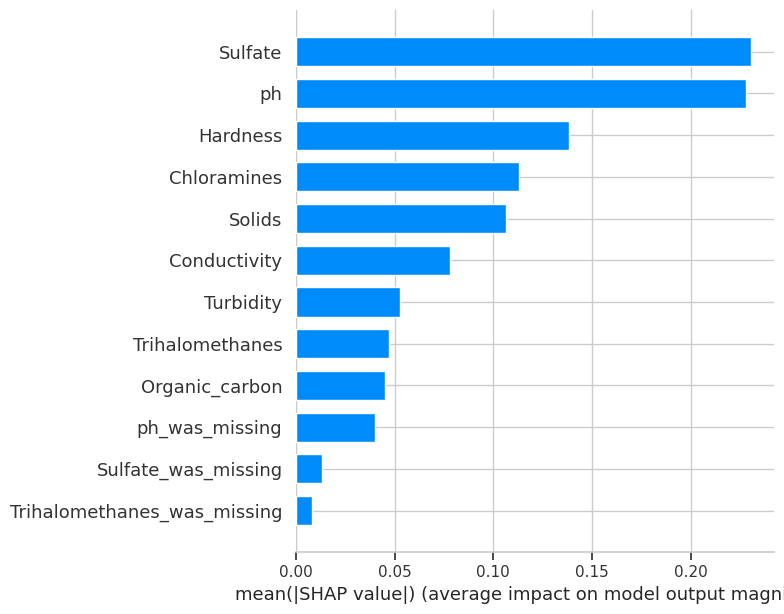

In [10]:
import shap
xgb = tuned["XGBoost"]
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(X_test)
plt.figure(); shap.summary_plot(sv, X_test, show=False); plt.title("SHAP summary (XGBoost, test set)")
plt.tight_layout(); plt.savefig(f"{OUT}/shap_summary.png", dpi=130, bbox_inches="tight"); plt.show()
plt.figure(); shap.summary_plot(sv, X_test, plot_type="bar", show=False)
plt.tight_layout(); plt.savefig(f"{OUT}/shap_bar.png", dpi=130, bbox_inches="tight"); plt.show()

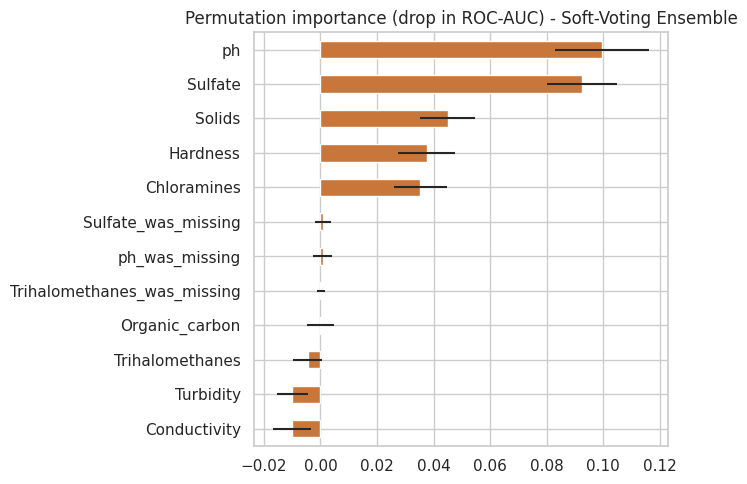

,importance,std
ph,0.0997,0.0166
Sulfate,0.0925,0.0123
Solids,0.0451,0.0097
Hardness,0.0376,0.0102
Chloramines,0.0353,0.0095
Sulfate_was_missing,0.0009,0.0027
ph_was_missing,0.0008,0.0034
Trihalomethanes_was_missing,0.0002,0.0014
Organic_carbon,0.0000,0.0047
Trihalomethanes,-0.0045,0.0052


In [11]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
pi_df = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=FEATURES).sort_values("importance")
pi_df.plot.barh(y="importance", xerr="std", legend=False, figsize=(7, 5), color="#c9763a")
plt.title(f"Permutation importance (drop in ROC-AUC) - {best_name}"); plt.tight_layout()
plt.savefig(f"{OUT}/permutation_importance.png", dpi=130); plt.show()
pi_df.sort_values("importance", ascending=False).round(4)

## 9. Save the model

In [12]:
final_model = best_model.fit(X_train, y_train)
joblib.dump(final_model, f"{MODELS}/best_model.joblib")
medians = train[BASE_FEATURES].median().to_dict()
test_row = results.loc[f"{best_name} (tuned threshold)"]
meta = {"model_name": best_name, "threshold": THRESHOLD, "features": FEATURES, "base_features": BASE_FEATURES,
        "train_medians": medians, "test_metrics": {k: round(float(test_row[k]), 4) for k in ["accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc"]},
        "feature_ranges": {c: [float(train[c].min()), float(train[c].max())] for c in BASE_FEATURES}}
json.dump(meta, open(f"{MODELS}/model_meta.json", "w"), indent=2)

open("predict_utils.py", "w").write('''
import json, joblib, pandas as pd

_model = joblib.load("models/best_model.joblib")
_meta = json.load(open("models/model_meta.json"))
BASE = _meta["base_features"]; FEATS = _meta["features"]; THR = _meta["threshold"]

def predict_potability(sample: dict) -> dict:
    # sample: raw water measurements, e.g. {"ph": 7.1, "Hardness": 190, ...}. Missing/None values are allowed
    # for ph, Sulfate, Trihalomethanes and are filled with the training median (flag set to 1), as in training.
    row = {}
    for c in BASE:
        v = sample.get(c)
        missing = v is None or v != v
        row[c] = _meta["train_medians"][c] if missing else float(v)
        if f"{c}_was_missing" in FEATS:
            row[f"{c}_was_missing"] = int(missing)
    X = pd.DataFrame([row])[FEATS]
    p = float(_model.predict_proba(X)[0, 1])
    return {"probability_potable": round(p, 4), "potable": bool(p >= THR), "threshold": THR}
''')
print("saved:", os.listdir(MODELS))
from predict_utils import predict_potability
print(predict_potability({"ph": 7.0, "Hardness": 190, "Solids": 20000, "Chloramines": 7, "Sulfate": None,
                          "Conductivity": 420, "Organic_carbon": 14, "Trihalomethanes": 66, "Turbidity": 4}))

saved: ['best_model.joblib', 'model_meta.json']
{'probability_potable': 0.353, 'potable': False, 'threshold': 0.38}
